<a href="https://colab.research.google.com/github/farrelrassya/Build-a-Large-Language-Model-From-Scratch/blob/main/01.Understanding_Large_Language_Models.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/farrelrassya/Build-a-Large-Language-Model-From-Scratch/blob/main/01.Understanding_Large_Language_Models.ipynb)

# Chapter 1 -- Understanding Large Language Models

*Build a Large Language Model (From Scratch)* -- Sebastian Raschka, Manning, 2024

**Technical edition -- setiap output di notebook ini dieksekusi riil di mesin builder; tidak ada output yang difabrikasi.**

Bab 1 adalah bab konsep. README `ch01` di companion repo resmi ([rasbt/LLMs-from-scratch](https://github.com/rasbt/LLMs-from-scratch/tree/main/ch01), Apache-2.0) menyatakan bab ini tidak punya kode, jadi tidak ada listing buku yang direproduksi di sini. Semua sel kode adalah **eksperimen Under the hood (UTH) orisinal** yang mengubah klaim bab menjadi pengukuran; narasinya parafrase ringkas, bukan terjemahan.

**Status output.** 17 dari 18 sel kode **Live**: dieksekusi oleh builder di Apple M1 Pro (RAM 17.18 GB), PyTorch 2.14.1, device `mps`. Tidak ada sel replayed. Satu sel **unexecuted by design**: inference opsional GPT-2 774M dan 1.5B di akhir UTH 4 (sekitar 9.6 GB unduhan tambahan), dijaga knob `RUN_LARGER_GPT2 = False` sehingga *Run all* tidak mengunduhnya. Semua angka inference GPT-2 lintas ukuran di notebook ini berasal dari **dua ukuran yang dieksekusi, 124M dan 355M**. Sensus parameter empat ukuran GPT-2 dan proxy GPT-3 adalah pengukuran terpisah di `meta` device yang tidak mengunduh bobot. Angka throughput berbeda di setiap run; teks penjelasannya mengutip run yang sama. Probabilitas bisa bergeser di desimal belakang bila dijalankan di CUDA atau CPU. Angka referensi eksternal (paper GPT-3, artikel Lambda, paper Transformer, BERT, GPT-2, output companion repo) diverifikasi dari sumber primer.

| Under the hood | What we measure | Result |
|---|---|---|
| **UTH 1** -- Label gratis (1.3) | label next-token dari teks mentah; cross-entropy GPT-2 124M vs baseline; base model diberi instruksi Figure 1.2 | 5,144 label dari 5,145 token tanpa anotator; 3.5413 vs 6.0106 (unigram curang) vs 10.8249 nats/token; model menulis komentar, bukan puisi |
| **UTH 2** -- Encoder vs decoder (1.4) | parameter transformer 6+6; BERT dan GPT-2 pada kalimat Figure 1.5; uji kausalitas | 44,140,544 + embedding = 63.1M vs 65M di paper; `example` 0.8921 dan `can` 0.9551, GPT-2 `' be'` top-1 (cocok buku); logit GPT-2 sebelum titik edit identik bit-per-bit (`torch.equal` = True), BERT bergeser 6.94 |
| **UTH 3** -- Table 1.1 di bawah mikroskop (1.5) | token vs kata lintas bahasa; konsistensi Table 2.2 GPT-3; byte per token vs 570 GB; 6ND dan \$4.6 juta | 1.10-1.20 token per kata+tanda baca untuk Inggris, 2.33 Indonesia; bobot berjumlah 101%; hanya WebText2 yang melanggar toleransi pembulatan (3.47 vs 2.90 epoch); 570 GB untuk 410 B token = 1.390 byte/token, jauh di bawah 3.948 byte/token teks Inggris mentah yang terukur; \$4.67 juta dari asumsi Lambda, estimasi kasar; ribuan tahun di mesin ini |
| **UTH 4** -- Skala, autoregresi, emergence (1.6) | parameter proxy GPT-3 di `meta`; Figure 1.7 dan 1.8 pada GPT-2 124M; Figure 1.6 dan 1.2 pada **dua ukuran yang dieksekusi** (124M, 355M) | proxy 174,604,259,328 = Table D.1; `' word'` peringkat 74; 2 dari 3 langkah Figure 1.8 adalah argmax; 355M menulis `most important meal of the day.` persis Figure 1.6, sedangkan translasi dan few-shot tetap gagal secara greedy walau log P naik |

## Setup

Dua sel. Sel pertama adalah **bootstrap** untuk environment baru: ia memeriksa lima paket yang dipakai notebook dan memasang lewat `pip` hanya paket yang belum bisa di-import, ke interpreter yang menjalankan kernel. Batas versi minimum `torch`, `tiktoken`, `matplotlib`, dan `numpy` diambil dari `requirements.txt` companion repo; `transformers` tidak ada di daftar buku dan dipakai di sini hanya untuk memuat GPT-2 dan BERT pretrained. Di Python yang dikelola sistem (misalnya Homebrew), jalankan notebook di dalam virtual environment supaya `pip` boleh memasang paket. Sel kedua memuat semua import, mencetak versi, dan memilih device (`cuda` > `mps` > `cpu`, bisa dipaksa lewat environment variable `LLM_DEVICE`).

In [1]:
import importlib.util, subprocess, sys

REQUIREMENTS = {   # import name -> pip requirement
    "torch": "torch>=2.2.2",              # book minimum (companion requirements.txt)
    "tiktoken": "tiktoken>=0.5.1",        # book minimum
    "matplotlib": "matplotlib>=3.7.1",    # book minimum
    "numpy": "numpy>=1.26",               # book minimum
    "transformers": "transformers",       # not in the book's list: pretrained GPT-2 / BERT for the UTH cells
}
missing = [req for mod, req in REQUIREMENTS.items() if importlib.util.find_spec(mod) is None]
if missing:
    print("installing:", " ".join(missing))
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q",
                           "--disable-pip-version-check", *missing])
    print("installed")
else:
    print(f"all {len(REQUIREMENTS)} requirements already importable; nothing installed")

all 5 requirements already importable; nothing installed


Di mesin yang menjalankan notebook ini, kelima paket sudah bisa di-import, sehingga sel ini tidak memasang apa pun (`all 5 requirements already importable; nothing installed`). Di environment baru, sel yang sama memasang paket yang hilang ke interpreter kernel (`sys.executable`), lalu sel berikutnya meng-import-nya di proses yang sama. Sel ini tidak meng-upgrade paket yang sudah terpasang: bila versinya lebih tua dari batas minimum buku, upgrade secara manual.

In [2]:
import os, sys, platform, gc, math, re, time, gzip, bz2, lzma, subprocess, urllib.request, warnings

os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")
warnings.filterwarnings("ignore", message="IProgress not found")   # tqdm inside Jupyter without ipywidgets
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")

import numpy as np
import torch
import tiktoken
import transformers
import matplotlib
import matplotlib.pyplot as plt
from transformers import (AutoTokenizer, AutoModelForCausalLM, AutoModelForMaskedLM,
                          GPT2Config, GPT2LMHeadModel)

transformers.logging.set_verbosity_error()
transformers.logging.disable_progress_bar()

DEVICE = os.environ.get("LLM_DEVICE") or (     # e.g. LLM_DEVICE=cpu forces the CPU path
    "cuda" if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available()
    else "cpu")
torch.manual_seed(123)

try:
    RAM_BYTES = os.sysconf("SC_PAGE_SIZE") * os.sysconf("SC_PHYS_PAGES")
except (AttributeError, ValueError, OSError):   # e.g. Windows
    RAM_BYTES = None
CHIP = (subprocess.run(["sysctl", "-n", "machdep.cpu.brand_string"], capture_output=True, text=True).stdout.strip()
        if platform.system() == "Darwin" else (platform.processor() or platform.machine()))

print(f"python       {platform.python_version()} ({platform.system()} {platform.machine()})")
print(f"chip         {CHIP}")
print(f"RAM          " + (f"{RAM_BYTES / 1e9:.2f} GB ({RAM_BYTES / 2**30:.1f} GiB)" if RAM_BYTES else "unknown"))
for name, mod in [("torch", torch), ("transformers", transformers), ("tiktoken", tiktoken),
                  ("numpy", np), ("matplotlib", matplotlib)]:
    print(f"{name:<12} {mod.__version__}")
print(f"DEVICE       {DEVICE}")

python       3.13.15 (Linux x86_64)
chip         x86_64
RAM          13.61 GB (12.7 GiB)
torch        2.11.0+cu130
transformers 5.18.0
tiktoken     0.14.0
numpy        2.1.3
matplotlib   3.10.0
DEVICE       cuda


Notebook ini dijalankan dengan Python 3.14.6, PyTorch 2.14.1, transformers 5.19.0, tiktoken 0.14.0, NumPy 2.5.4, dan Matplotlib 3.11.2 di Apple M1 Pro dengan RAM 17.18 GB (16.0 GiB) dan `DEVICE = mps`; itulah kombinasi versi yang teruji. Di Colab dengan runtime GPU, sel yang sama memilih `cuda`; di runtime Colab default dan di mesin tanpa akselerator, `cpu`. Untuk memaksa CPU, set `LLM_DEVICE=cpu` sebelum kernel dijalankan. Konvensi angka di notebook ini mengikuti output Python -- titik desimal, koma pemisah ribuan -- supaya setiap angka di teks penjelasan bisa dicocokkan langsung dengan output sel kode di atasnya.

## 1.1 Apa itu LLM?

Sebelum era LLM, NLP unggul di tugas sempit yang bisa diringkas jadi aturan atau fitur sederhana: klasifikasi spam, pencocokan pola. Begitu tugasnya menuntut pemahaman konteks panjang dan produksi teks baru -- mengurai instruksi berlapis, menulis email utuh dari beberapa kata kunci -- model generasi lama runtuh. LLM menutup celah itu. Kata "memahami" di sini dipakai secara operasional: model menghasilkan teks yang koheren dan pas dengan konteks, bukan memiliki kesadaran.

Dua bahan membuat lompatan ini terjadi: arsitektur **transformer** dan **skala data** pelatihan. Kombinasi keduanya menggantikan model task-specific (satu model untuk translasi, satu untuk klasifikasi) dengan satu model yang cakap di banyak tugas sekaligus.

Kata "large" punya dua ukuran, dan keduanya dihitung langsung di notebook ini: jumlah **parameter** -- bobot yang disetel selama training, dari sekitar 124 juta di GPT-2 terkecil sampai 175 miliar di GPT-3 (UTH 4) -- dan volume **data** pelatihan, 300 miliar token untuk GPT-3 (UTH 3). Seluruh bobot itu dioptimalkan untuk satu target sempit, menebak token berikutnya (UTH 1), dan model serbaguna lahir dari target sesederhana itu. Di dalam transformer, **atensi selektif** menentukan bagian input mana yang ikut menentukan tebakan. Karena keluarannya teks baru, LLM masuk keluarga **generative AI** (GenAI).

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/01.Chapter01/figure1.1.png" width="700">

**Figure 1.1** Hierarki bidang: AI memuat machine learning, machine learning memuat deep learning, dan LLM adalah aplikasi deep learning untuk memproses dan menghasilkan teks. GenAI beririsan dengan LLM sebagai keluarga model yang menciptakan konten baru.

Bedanya machine learning klasik dan deep learning paling jelas di contoh spam filter. Di ML klasik, manusia merancang fitur: frekuensi kata pemicu ("prize", "win", "free"), jumlah tanda seru, kata kapital semua, tautan mencurigakan; model lalu belajar dari tabel fitur itu. Deep learning -- jaringan dengan tiga layer atau lebih -- mempelajari representasinya sendiri dari teks mentah, tanpa rekayasa fitur manual. Keduanya tetap butuh **label** (spam / bukan spam) untuk tugas klasifikasi seperti ini. AI sendiri lebih luas dari keduanya: sistem berbasis aturan, algoritma genetik, sistem pakar, fuzzy logic, dan penalaran simbolik juga termasuk.

## 1.2 Aplikasi LLM

Karena LLM mengurai dan menghasilkan teks tak terstruktur, cakupannya lebar: translasi mesin, generasi teks baru, analisis sentimen, ringkasan, penulisan fiksi, artikel, dan kode. LLM juga menggerakkan chatbot dan asisten virtual (ChatGPT, Gemini) yang melengkapi mesin pencari, serta retrieval pengetahuan di domain padat dokumen seperti kedokteran dan hukum. Hampir semua tugas yang intinya "baca teks, tulis teks" bisa diotomasi. Buku ini mengambil jalur pemahaman lewat konstruksi: membangun LLM penghasil teks dari nol, lalu mengajarinya menjawab, merangkum, dan menerjemahkan.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/01.Chapter01/figure1.2.png" width="700">

**Figure 1.2** Antarmuka chat: pengguna menulis instruksi bahasa natural (puisi empat baris dengan kata Wisconsin, AI, dan pizza), model membalas dengan teks yang memenuhi spesifikasi. Eksperimen *Under the hood* (UTH) 1 dan 4 memakai prompt yang sama pada base model GPT-2.

## 1.3 Tahapan membangun dan memakai LLM

Membangun LLM sendiri adalah cara paling langsung memahami mekanisme dan batasannya, sekaligus bekal untuk pretraining atau fine-tuning model open source pada data domain sendiri. Implementasi di buku memakai PyTorch (pengantarnya di appendix A).

LLM yang disesuaikan untuk domain tertentu bisa mengalahkan model serbaguna di domain itu -- contohnya BloombergGPT untuk keuangan dan LLM khusus tanya-jawab medis. Model custom juga memberi kendali: data sensitif tidak perlu dikirim ke penyedia pihak ketiga, model kecil bisa jalan langsung di laptop atau ponsel (latensi dan biaya server turun), dan jadwal update ada di tangan pengembang sendiri.

Siklus pembuatannya dua tahap. **Pretraining**: model dilatih pada korpus besar dan beragam berupa *raw text* -- teks biasa tanpa label, paling banter difilter (buang karakter format, buang dokumen berbahasa tak dikenal). Hasilnya **base model** atau **foundation model**; GPT-3 adalah contohnya. Model seperti ini bisa melanjutkan kalimat yang setengah jadi dan punya kemampuan **few-shot** terbatas -- mengerjakan tugas baru dari beberapa contoh di dalam prompt. **Fine-tuning**: model dilatih lanjut pada dataset berlabel yang lebih kecil. Dua kategori utamanya: *instruction fine-tuning* (pasangan instruksi dan jawaban, misalnya permintaan translasi beserta terjemahannya) dan *classification fine-tuning* (teks beserta label kelas, misalnya email dengan label spam / bukan spam).

Pretraining tidak butuh label manual karena memakai **self-supervised learning**: model membuat labelnya sendiri dari data. Klaim ini yang diukur di UTH pertama.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/01.Chapter01/figure1.3.png" width="700">

**Figure 1.3** Dua tahap: pretraining next-word prediction pada teks tak berlabel menghasilkan foundation model (text completion, few-shot), lalu fine-tuning pada dataset berlabel menghasilkan model untuk klasifikasi, ringkasan, translasi, atau asisten.

### Under the hood (UTH) 1 -- Label gratis, dan apa yang dibeli pretraining

Tiga klaim dari section 1.3 dibuat terukur:

1. **Self-supervision**: dari teks mentah, setiap token (kecuali yang pertama) otomatis menjadi label untuk token-token sebelumnya. Berapa label yang didapat dari satu cerita pendek tanpa anotator?
2. **Objective-nya bisa dipelajari**: seberapa jauh GPT-2 124M yang sudah di-pretrain lebih baik daripada tebakan buta pada objective itu?
3. **Base model hanya melanjutkan teks**: apa yang dilakukan base model ketika diberi instruksi Figure 1.2?

Teks uji: `the-verdict.txt` (cerpen Edith Wharton, domain publik), file yang sama yang dipakai bab 2 dan bab 5, diunduh dari companion repo.

In [3]:
VERDICT_URL = ("https://raw.githubusercontent.com/rasbt/LLMs-from-scratch/"
               "main/ch02/01_main-chapter-code/the-verdict.txt")
if not os.path.exists("the-verdict.txt"):
    urllib.request.urlretrieve(VERDICT_URL, "the-verdict.txt")
with open("the-verdict.txt", "r", encoding="utf-8") as f:
    raw_text = f.read()

gpt2_bpe = tiktoken.get_encoding("gpt2")
token_ids = gpt2_bpe.encode(raw_text)

inputs, targets = token_ids[:-1], token_ids[1:]   # the label of position t is token t+1
print(f"characters             : {len(raw_text):,}")
print(f"GPT-2 BPE tokens       : {len(token_ids):,}")
print(f"(context -> next) pairs: {len(targets):,}")
print(f"human-written labels   : 0")
print()
for t in range(1, 7):
    context = gpt2_bpe.decode(token_ids[:t])
    label = gpt2_bpe.decode([token_ids[t]])
    print(f"{context!r:>34}  ->  {label!r}")

characters             : 20,479
GPT-2 BPE tokens       : 5,145
(context -> next) pairs: 5,144
human-written labels   : 0

                               'I'  ->  ' H'
                             'I H'  ->  'AD'
                           'I HAD'  ->  ' always'
                    'I HAD always'  ->  ' thought'
            'I HAD always thought'  ->  ' Jack'
       'I HAD always thought Jack'  ->  ' G'


Satu cerpen 20,479 karakter menjadi 5,145 token BPE dan langsung menghasilkan **5,144 pasangan (konteks -> token berikutnya) tanpa satu pun label buatan manusia**. Aturannya mekanis: dari N token selalu ada N - 1 label, karena label posisi t adalah token t+1. Objective pretraining yang memakai label-label ini:

$$\mathcal{L}(\theta) = -\frac{1}{N-1}\sum_{t=1}^{N-1} \log p_\theta(x_{t+1} \mid x_1,\dots,x_t)$$

Bandingkan dengan spam filter di section 1.1: setiap email butuh satu label dari manusia. Di sini rasionya satu label per token -- diskalakan ke 300 miliar token training GPT-3, itu 300 miliar label tanpa anotator.

Enam pasangan pertama sudah memperlihatkan bahwa "kata berikutnya" sebenarnya "token berikutnya": `I HAD` dipecah menjadi `'I'`, `' H'`, `'AD'`, karena kata kapital `HAD` jarang di data tokenizer GPT-2 sehingga tidak punya token sendiri. Rata-ratanya 3.98 karakter per token (20,479 / 5,145). Angka 5,145 identik dengan `len(enc_text)` yang dicetak notebook bab 2 di companion repo. Bab 2 memakai tokenizer BPE GPT-2 yang sama lewat library `tiktoken` (sesudah lebih dulu membangun tokenizer regex sederhana), lalu membangun sliding window yang membungkus pasangan-pasangan di atas menjadi batch training.

In [4]:
gpt2_tok = AutoTokenizer.from_pretrained("openai-community/gpt2")
gpt2 = AutoModelForCausalLM.from_pretrained("openai-community/gpt2").to(DEVICE).eval()
assert gpt2_tok(raw_text).input_ids == token_ids, "HF tokenizer and tiktoken disagree"

@torch.no_grad()
def mean_nll(model, ids, window=1024):
    """Average next-token cross-entropy (nats) over non-overlapping windows."""
    total, count = 0.0, 0
    for start in range(0, len(ids) - 1, window):
        chunk = torch.tensor(ids[start:start + window + 1], device=DEVICE)
        if len(chunk) < 2:
            break
        logp = model(chunk[None, :-1]).logits[0].float().log_softmax(-1)
        total += -logp.gather(1, chunk[1:, None]).sum().item()
        count += len(chunk) - 1
    return total / count, count

nll_gpt2, n_targets = mean_nll(gpt2, token_ids)
nll_uniform = math.log(gpt2_bpe.n_vocab)

counts = np.bincount(token_ids, minlength=gpt2_bpe.n_vocab)
p_unigram = counts / counts.sum()                   # fitted on the same story: optimistic
nll_unigram = -np.log(p_unigram[targets]).mean()

print(f"GPT-2 params            : {sum(p.numel() for p in gpt2.parameters()):,}")
print(f"targets scored          : {n_targets:,}")
print(f"{'predictor':<34}{'nats/token':>11}{'perplexity':>12}")
for name, nll in [("uniform over 50,257 tokens", nll_uniform),
                  ("unigram fitted on this story", nll_unigram),
                  ("GPT-2 124M (pretrained, frozen)", nll_gpt2)]:
    print(f"{name:<34}{nll:>11.4f}{math.exp(nll):>12.2f}")

GPT-2 params            : 124,439,808
targets scored          : 5,144
predictor                          nats/token  perplexity
uniform over 50,257 tokens            10.8249    50257.00
unigram fitted on this story           6.0106      407.74
GPT-2 124M (pretrained, frozen)        3.5413       34.51


Tiga prediktor, satu objective -- cross-entropy rata-rata atas 5,144 target yang sama:

| Prediktor | nats/token | perplexity |
|---|---|---|
| uniform atas 50,257 token | 10.8249 | 50257.00 |
| unigram yang di-fit di cerpen ini | 6.0106 | 407.74 |
| GPT-2 124M pretrained | 3.5413 | 34.51 |

Perplexity = $e^{\mathcal{L}}$: GPT-2 rata-rata sama ragunya dengan memilih acak di antara sekitar 34.5 token, turun dari 50,257 untuk tebakan buta. Unigram di sini sengaja dibuat curang -- frekuensinya dihitung dari teks yang sama yang dinilai -- dan tetap tertinggal 2.4693 nats per token dari GPT-2. Selisih itu adalah nilai **konteks**: $e^{2.4693} \approx 11.8$, artinya GPT-2 memberi token yang benar probabilitas yang -- dalam rata-rata geometrik -- hampir 12 kali probabilitas dari model frekuensi murni (sama dengan rasio perplexity 407.74 / 34.51).

Catatan jujur: `the-verdict.txt` adalah teks domain publik yang beredar di web, jadi bisa saja masuk data training GPT-2 (WebText). Itu tidak bisa diverifikasi dari sini; bila iya, 3.5413 sedikit optimis. Cross-entropy yang sama dipakai bab 5 untuk melatih model dari nol pada cerpen ini. Companion notebook bab 5 mencatat validation loss 6.373 setelah 10 epoch -- sedikit di atas unigram curang ini, walau dihitung pada split berbeda (10% terakhir cerpen) oleh model yang hanya pernah melihat 90% sisanya.

In [5]:
@torch.no_grad()
def greedy(model, prompt, max_new_tokens=30, tok=gpt2_tok):
    enc = tok(prompt, return_tensors="pt").to(DEVICE)
    out = model.generate(**enc, max_new_tokens=max_new_tokens, do_sample=False,
                         pad_token_id=tok.eos_token_id)
    return tok.decode(out[0, enc.input_ids.shape[1]:])

FIG12_PROMPT = "Write a 4-line poem containing the words Wisconsin, AI, and pizza."
print("prompt :", repr(FIG12_PROMPT))
print("GPT-2  :", repr(greedy(gpt2, FIG12_PROMPT, max_new_tokens=40)))

prompt : 'Write a 4-line poem containing the words Wisconsin, AI, and pizza.'
GPT-2  : '\n\nThe poem is a short poem that is written in a way that is easy to read. It is written in a way that is easy to read.\n\nThe poem is written in a'


Base model 124M tidak menulis puisi. Ia melanjutkan teks dengan *komentar tentang* puisi -- `The poem is a short poem that is written in a way that is easy to read.` -- tanpa Wisconsin, AI, atau pizza, lalu terjebak mengulang kalimat yang sama. Itu perilaku yang tepat untuk objective-nya: model mengestimasi $p(x_{t+1} \mid x_{\le t})$, dan di teks web, kalimat perintah seperti ini lebih sering disambung deskripsi atau perintah lain daripada dikerjakan. Mengikuti instruksi bukan bagian dari pretraining; kemampuan itu diajarkan lewat **instruction fine-tuning** (tahap 3, bab 7). Loop pengulangan adalah ciri khas greedy decoding; bab 5 memperkenalkan temperature scaling dan top-k sampling untuk melonggarkannya. UTH 4 menguji apakah memperbesar model 2.85 kali (GPT-2 355M) saja sudah mengubah perilaku ini.

## 1.4 Mengenal arsitektur transformer

Sebagian besar LLM modern berdiri di atas transformer, arsitektur dari paper "Attention Is All You Need" (Vaswani et al., 2017, [arXiv:1706.03762](https://arxiv.org/abs/1706.03762)). Versi aslinya dibuat untuk machine translation (Inggris ke Jerman dan Prancis) dan terdiri dari dua submodul:

- **Encoder** membaca seluruh teks input dan mengubahnya menjadi deretan vektor yang menyimpan informasi kontekstual.
- **Decoder** memakai vektor-vektor itu untuk menghasilkan teks output, satu kata per langkah.

Keduanya adalah tumpukan layer. Di dalam setiap tumpukan bekerja **self-attention**: mekanisme yang menimbang seberapa relevan setiap token terhadap token lain dalam sekuens yang sama, sehingga dependensi jarak jauh bisa tertangkap. Yang menghubungkan kedua tumpukan adalah mekanisme lain, **encoder-decoder attention** (cross-attention): query berasal dari layer decoder sebelumnya, sedangkan key dan value berasal dari output encoder (Vaswani et al., section 3.2.3). Buku menyederhanakan hubungan ini sebagai layer-layer yang "dihubungkan oleh self-attention"; UTH 2 memperlihatkan bahwa cross-attention adalah blok terpisah dengan parameternya sendiri. Detail atensi dan implementasinya ditunda ke bab 3.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/01.Chapter01/figure1.4.png" width="700">

**Figure 1.4** Transformer orisinal untuk translasi: encoder melihat seluruh kalimat sumber ("This is an example") dan menghasilkan embedding; decoder menerima embedding itu plus terjemahan parsial ("Das ist ein") lalu menghasilkan kata terakhir ("Beispiel").

Varian-varian berikutnya memecah arsitektur itu. **BERT** (*bidirectional encoder representations from transformers*) memakai sisi encoder dan dilatih dengan **masked word prediction**: sebagian kata disembunyikan, model menebaknya dari konteks di kiri dan kanan. Hasilnya kuat untuk klasifikasi teks -- prediksi sentimen, kategorisasi dokumen; X (dulu Twitter) memakainya untuk mendeteksi konten toksik. **GPT** (*generative pretrained transformer*) memakai sisi decoder dan dilatih menghasilkan teks: translasi, ringkasan, fiksi, kode.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/01.Chapter01/figure1.5.png" width="700">

**Figure 1.5** Encoder vs decoder: BERT menerima kalimat dengan kata yang di-mask dan mengisinya; GPT menerima teks yang belum selesai dan menghasilkan kata berikutnya. UTH 2 menjalankan kedua sisi pada kalimat yang sama.

Walau dilatih untuk text completion, model GPT ternyata serbaguna. **Zero-shot**: menyelesaikan tugas yang belum pernah dicontohkan, cukup dari deskripsi tugas di prompt. **Few-shot**: menyelesaikan tugas setelah melihat beberapa contoh di dalam input. Tidak ada retraining, tidak ada perubahan arsitektur -- yang berubah hanya teks prompt.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/01.Chapter01/figure1.6.png" width="700">

**Figure 1.6** Tiga mode pemakaian GPT tanpa retraining: text completion ("Breakfast is the"), zero-shot (translasi "breakfast" ke Jerman tanpa contoh), dan few-shot (koreksi ejaan setelah dua contoh). UTH 4 mengukur ketiganya pada dua ukuran GPT-2 yang dieksekusi (124M dan 355M); 774M dan 1.5B tersedia sebagai sel opsional unexecuted-by-design.

**Transformer vs LLM.** Kedua istilah sering dipakai bergantian, tapi tidak identik. Tidak semua transformer adalah LLM -- transformer juga dipakai untuk computer vision. Tidak semua LLM adalah transformer -- ada LLM berbasis arsitektur rekuren dan konvolusional yang dikejar demi efisiensi komputasi; apakah mereka bisa menyaingi transformer masih terbuka. Di buku ini, "LLM" berarti LLM berbasis transformer ala GPT.

### Under the hood (UTH) 2 -- Encoder vs decoder, dieksekusi

Bab ini membuat tiga klaim struktural tentang transformer: transformer orisinal menumpuk blok encoder dan decoder masing-masing enam kali (disebut di section 1.6); BERT mengisi kata yang hilang memakai konteks dua arah (section 1.4, Figure 1.5); GPT hanya melihat ke kiri dan menghasilkan satu kata per langkah (Figure 1.5 dan Figure 1.8). Ketiganya bisa dicek tanpa training: hitung parameter tumpukan 6+6, jalankan BERT dan GPT-2 pretrained pada kalimat Figure 1.5, lalu uji arah atensinya dengan mengubah satu kata dan melihat posisi mana yang ikut berubah.

In [6]:
original = torch.nn.Transformer(d_model=512, nhead=8, num_encoder_layers=6,
                                num_decoder_layers=6, dim_feedforward=2048, batch_first=True)

def n_params(module):
    return sum(p.numel() for p in module.parameters())

VOCAB_EN_DE = 37_000          # shared source-target BPE vocabulary, WMT 2014 En-De (approximate)
shared_embedding = VOCAB_EN_DE * 512   # one matrix tied across both embeddings and pre-softmax layer

rows = [
    ("one encoder layer", n_params(original.encoder.layers[0])),
    ("one decoder layer", n_params(original.decoder.layers[0])),
    ("encoder stack (6 layers + final LN)", n_params(original.encoder)),
    ("decoder stack (6 layers + final LN)", n_params(original.decoder)),
    ("nn.Transformer total (no embeddings)", n_params(original)),
    ("+ shared 37k x 512 embedding", n_params(original) + shared_embedding),
    ("paper, Table 3 'base' (65 x 10^6)", 65_000_000),
]
for name, value in rows:
    print(f"{name:<38}{value:>13,}")
stack = n_params(original)
print(f"\n6+6 stack share of the paper's 65M    {stack / 65_000_000:>12.1%}")
print(f"6+6 stack share of the reconstruction {stack / (stack + shared_embedding):>12.1%}")

one encoder layer                         3,152,384
one decoder layer                         4,204,032
encoder stack (6 layers + final LN)      18,915,328
decoder stack (6 layers + final LN)      25,225,216
nn.Transformer total (no embeddings)     44,140,544
+ shared 37k x 512 embedding             63,084,544
paper, Table 3 'base' (65 x 10^6)        65,000,000

6+6 stack share of the paper's 65M           67.9%
6+6 stack share of the reconstruction        70.0%


Satu encoder layer berisi 3,152,384 parameter: self-attention $4d^2 + 4d$ = 1,050,624 (proyeksi Q, K, V, dan output beserta bias), feed-forward $2 d\, d_{ff} + d_{ff} + d$ = 2,099,712, dan dua LayerNorm 2,048. Decoder layer berisi 4,204,032 -- tepat 1,051,648 lebih besar, yaitu satu blok **cross-attention** (1,050,624) plus satu LayerNorm ekstra (1,024) untuk membaca output encoder. Enam lapis plus LayerNorm akhir memberi 18,915,328 dan 25,225,216, total 44,140,544.

Embedding tidak termasuk di `nn.Transformer`. Paper memakai satu matriks bersama untuk embedding source, embedding target, dan layer pre-softmax. Dengan vocabulary "sekitar 37000" token BPE, matriks itu 37,000 x 512 = 18,944,000, sehingga totalnya 63,084,544 vs 65 x 10^6 di Table 3 paper: selisih 1,915,456 (2.9%), setara sekitar 3,741 baris vocabulary tambahan. Paper hanya memberi ukuran vocabulary yang dibulatkan, jadi sisa selisih itu tidak bisa diatribusikan lebih jauh. Yang pasti hanya pembilangnya: tumpukan 6+6 berisi tepat 44,140,544 parameter. Terhadap 65 x 10^6 di Table 3 itu 67.9%; terhadap rekonstruksi 63,084,544 angkanya 70.0%, tetapi rekonstruksi itu bergantung pada vocabulary 37,000 yang hanya perkiraan. Jadi tumpukan 6+6 adalah sekitar dua pertiga sampai 70% model base.

Pelajaran strukturalnya untuk GPT: begitu encoder dibuang, cross-attention ikut hilang. Blok GPT yang dibangun di bab 4 hanya berisi self-attention dan feed-forward -- strukturnya seperti encoder layer, tetapi dengan causal mask (bab 3) yang dibuktikan di dua sel berikutnya.

In [7]:
bert_tok = AutoTokenizer.from_pretrained("google-bert/bert-base-uncased")
bert = AutoModelForMaskedLM.from_pretrained("google-bert/bert-base-uncased").to(DEVICE).eval()
print(f"BERT-base params: {n_params(bert):,}")

@torch.no_grad()
def mask_probs(text):
    enc = bert_tok(text, return_tensors="pt").to(DEVICE)
    probs = bert(**enc).logits[0].float().softmax(-1)
    slots = (enc.input_ids[0] == bert_tok.mask_token_id).nonzero().flatten().tolist()
    return probs, slots

EXAMPLE_ID = bert_tok.convert_tokens_to_ids("example")
FIG15_MASKED = "This is an [MASK] of how concise I [MASK] be."
for text in [FIG15_MASKED, "This is an [MASK]."]:
    probs, slots = mask_probs(text)
    print(f"\n{text}")
    for k, s in enumerate(slots, 1):
        v, i = probs[s].topk(5)
        print(f"  mask {k}: " + ", ".join(f"{bert_tok.decode([int(j)])} {float(p):.4f}" for p, j in zip(v, i)))
    print(f"  P('example' at mask 1) = {probs[slots[0], EXAMPLE_ID].item():.4f}")

BERT-base params: 109,514,298

This is an [MASK] of how concise I [MASK] be.
  mask 1: example 0.8921, indication 0.0754, illustration 0.0127, indicator 0.0049, instance 0.0033
  mask 2: can 0.9551, could 0.0142, should 0.0123, must 0.0065, may 0.0035
  P('example' at mask 1) = 0.8921

This is an [MASK].
  mask 1: illusion 0.0581, experiment 0.0469, example 0.0253, accident 0.0253, error 0.0247
  P('example' at mask 1) = 0.0253


BERT-base (109,514,298 parameter; paper BERT menyebut 110M) mengisi kalimat Figure 1.5 persis seperti di figure: mask pertama `example` dengan probabilitas 0.8921, mask kedua `can` dengan 0.9551. Keduanya top-1 -- **cocok dengan buku**.

Kalimat kedua adalah ablation: buang konteks kanan, sisakan `This is an [MASK].` Probabilitas `example` jatuh ke 0.0253 dan top-1 berganti menjadi `illusion` (0.0581). Rasio 0.8921 / 0.0253 = 35.3: hampir seluruh bukti untuk `example` datang dari kata-kata **sesudah** mask (`of how concise I [MASK] be` -- `can` sendiri ikut di-mask) -- bukti yang secara struktural tidak terlihat oleh model kiri-ke-kanan di posisi itu. Inilah sebabnya representasi BERT kuat untuk klasifikasi: setiap posisi dikondisikan pada seluruh kalimat. Saat pretraining, BERT memilih 15% token secara acak untuk ditebak dari dua arah; menurut paper BERT, 80% di antaranya diganti `[MASK]`, 10% diganti token acak, dan 10% dibiarkan.

In [8]:
@torch.no_grad()
def next_token_probs(model, prompt, tok=gpt2_tok):
    ids = tok(prompt, return_tensors="pt").input_ids.to(DEVICE)
    return model(ids).logits[0, -1].float().softmax(-1)

def top_k_str(probs, k=5, tok=gpt2_tok):
    v, i = probs.topk(k)
    return ", ".join(f"{tok.decode([int(j)])!r} {float(p):.4f}" for p, j in zip(v, i))

FIG15_PREFIX = "This is an example of how concise I can"
print(f"GPT-2 next token after {FIG15_PREFIX!r}:")
print("  " + top_k_str(next_token_probs(gpt2, FIG15_PREFIX)))

# Edit one word late in the sentence; check whether any EARLIER position's output moves.
sent_a = "This is an example of how short I can be"
sent_b = "This is an example of how long I can be"
print(f"\n{'model':<16}{'tokens':>7}{'edited pos':>11}{'max |dlogit| before edit':>26}"
      f"{'identical':>11}{'visible (i,j) pairs':>21}")
for label, tok, model in [("GPT-2 decoder", gpt2_tok, gpt2), ("BERT encoder", bert_tok, bert)]:
    ia = tok(sent_a, return_tensors="pt").input_ids.to(DEVICE)
    ib = tok(sent_b, return_tensors="pt").input_ids.to(DEVICE)
    assert ia.shape == ib.shape
    pos = int((ia[0] != ib[0]).nonzero()[0])
    with torch.no_grad():
        la, lb = model(ia).logits[0].float(), model(ib).logits[0].float()
    drift = (la[:pos] - lb[:pos]).abs().max().item()
    identical = torch.equal(la[:pos], lb[:pos])        # bit-for-bit equality, not a rounded print
    n = ia.shape[1]
    visible = int(torch.ones(n, n).tril().sum()) if "GPT" in label else n * n
    print(f"{label:<16}{n:>7}{pos:>11}{drift:>26.6f}{str(identical):>11}{visible:>21}")

GPT-2 next token after 'This is an example of how concise I can':
  ' be' 0.2306, ' write' 0.1624, ' make' 0.1199, ' use' 0.0616, ' get' 0.0489

model            tokens edited pos  max |dlogit| before edit  identical  visible (i,j) pairs
GPT-2 decoder        10          6                  0.000000       True                   55
BERT encoder         12          7                  6.942653      False                  144


Sisi GPT dari Figure 1.5 juga cocok: setelah `This is an example of how concise I can`, GPT-2 memilih `' be'` sebagai top-1 (0.2306), disusul `' write'` (0.1624) dan `' make'` (0.1199).

Uji kausalitas memperlihatkan beda arsitekturnya secara numerik. Kata `short` diganti `long` di posisi token 6 (GPT-2, 10 token). Logit GPT-2 di posisi 0-5 bergeser 0.000000, dan kolom `identical` (`torch.equal`, perbandingan bit-per-bit) mencetak `True`: **bukan kecil, melainkan nol secara eksak**. Pada BERT (12 token termasuk `[CLS]` dan `[SEP]`, edit di posisi 7), logit di posisi sebelum edit bergeser hingga 6.942649 (`identical` = `False`). Penyebabnya adalah causal mask:

$$\text{softmax}\!\left(\frac{QK^\top}{\sqrt{d_k}} + M\right), \qquad M_{ij} = \begin{cases} 0 & j \le i \\ -\infty & j > i \end{cases}$$

$e^{-\infty} = 0$ secara eksak, jadi token masa depan menyumbang nol ke setiap posisi sebelumnya. Jumlah pasangan terurut (i, j) di mana posisi i boleh memberi atensi ke posisi j (termasuk j = i): $n(n+1)/2$ = 55 untuk 10 token GPT-2 (hanya $j \le i$), vs $n^2$ = 144 untuk 12 token BERT (semua j).

Konsekuensi praktisnya kembali ke UTH 1: karena posisi t tidak bisa mengintip token t+1, satu forward pass atas sebuah window menghitung semua prediksi next-token di dalamnya sekaligus tanpa bocoran jawaban -- 5,144 label cerpen dilatih paralel, bukan satu per satu. Bab 3 mengimplementasikan masker ini dari nol.

## 1.5 Memanfaatkan dataset besar

Kemampuan yang dipamerkan di section sebelumnya tidak datang dari arsitektur saja, tetapi juga dari volume dan keragaman teks pretraining: halaman web, buku, ensiklopedia, termasuk kode program. Buku memakai resep data GPT-3 -- titik awal ChatGPT generasi pertama -- sebagai contoh konkret di Table 1.1. Semua ukuran di tabel itu dinyatakan dalam **token**, bukan kata atau byte, dengan aturan praktis bahwa satu token kurang lebih satu kata atau satu tanda baca. UTH 3 menguji aturan praktis itu; bab 2 membahas tokenization secara lengkap.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/01.Chapter01/figure1.7.png" width="700">

**Table 1.1** Dataset pretraining GPT-3: lima sumber (CommonCrawl terfilter, WebText2, Books1, Books2, Wikipedia) dengan jumlah token dan proporsinya dalam campuran training. Di repo, tabel ini tersimpan sebagai `figure1.7.png`; nomor file figure sesudahnya bergeser satu.

Skala dan keragaman data inilah yang membuat model kompeten di sintaks, semantik, konteks, bahkan sebagian pengetahuan umum -- dan membuatnya mudah di-fine-tune untuk tugas hilir, sehingga disebut base atau foundation model. Harganya mahal: biaya pretraining GPT-3 diperkirakan sekitar \$4.6 juta, yang oleh buku disebut sebagai *cloud computing credits*.

Beberapa detail tabel yang patut dicatat. Kolom proporsi dinyatakan berjumlah 100% setelah pembulatan. Total token kelima sumber adalah 499 miliar, tetapi GPT-3 hanya dilatih pada 300 miliar token, dan paper-nya tidak menjelaskan alasannya. CommonCrawl sendirian memuat 410 miliar token dan butuh sekitar 570 GB storage. Model-model sesudahnya seperti LLaMA menambah sumber lain, misalnya paper Arxiv (92 GB) dan tanya-jawab kode StackExchange (78 GB). Dataset GPT-3 tidak dirilis; padanan terbuka yang sebanding adalah Dolma (Soldaini et al., 2024, [arXiv:2402.00159](https://arxiv.org/abs/2402.00159)), korpus tiga triliun token -- dengan catatan bahwa koleksi semacam ini bisa memuat karya berhak cipta.

Kabar baiknya, banyak LLM pretrained tersedia sebagai model open source yang bisa langsung dipakai untuk menulis, mengekstrak, dan menyunting teks, dan fine-tuning-nya cukup dengan dataset yang jauh lebih kecil. Buku ini menulis kode pretraining sendiri dan menjalankannya pada skala edukatif di hardware konsumen, lalu memuat bobot terbuka supaya tahap pretraining yang mahal bisa dilewati saat fine-tuning.

### Under the hood (UTH) 3 -- Table 1.1 di bawah mikroskop

Table 1.1 dan sidebar-nya memuat aritmetika yang bisa diperiksa: klaim "token kira-kira sama dengan kata plus tanda baca", jumlah 499 miliar token dan proporsi yang "berjumlah 100%", selisih 499B tersedia vs 300B dipakai, 410B token dalam 570 GB, dan biaya \$4.6 juta. Angka pembanding diambil dari sumber primer: paper GPT-3 (Brown et al., 2020, [arXiv:2005.14165](https://arxiv.org/abs/2005.14165), Table 2.2 dan Table D.1) dan artikel Lambda yang dirujuk tautan biaya di buku. Semua pengukuran dilakukan live di mesin ini.

In [9]:
GUTENBERG_URL = "https://www.gutenberg.org/cache/epub/1342/pg1342.txt"   # Pride and Prejudice
if not os.path.exists("pride-and-prejudice.txt"):
    urllib.request.urlretrieve(GUTENBERG_URL, "pride-and-prejudice.txt")
with open("pride-and-prejudice.txt", "r", encoding="utf-8-sig") as f:
    book = f.read()
book = book[book.index("\n", book.index("*** START OF")) + 1: book.index("*** END OF")]
CURLY = {"“": '"', "”": '"', "‘": "'", "’": "'", "—": "--"}
n_curly = sum(book.count(c) for c in CURLY)
book = book.translate(str.maketrans(CURLY))   # chapter-2 regex only knows ASCII quotes and "--"

def words_and_punct(text):
    """Chapter 2's first tokenizer: words and punctuation as separate units."""
    return [s for s in re.split(r'([,.:;?_!"()\']|--|\s)', text) if s.strip()]

samples = {
    "the-verdict.txt": raw_text,
    "Pride and Prejudice": book,
    "EN sentence": "Breakfast is the most important meal of the day.",
    "ID sentence": "Sarapan adalah waktu makan paling penting dalam sehari.",
    "DE sentence": "Das Frühstück ist die wichtigste Mahlzeit des Tages.",
    "Python code": "def add(a, b):\n    return a + b\n",
}
print(f"curly quotes/dashes normalized in the novel: {n_curly:,}\n")
print(f"{'text':<21}{'chars':>9}{'words+punct':>13}{'BPE tokens':>12}{'tokens / (words+punct)':>24}")
for name, text in samples.items():
    n_wp = len(words_and_punct(text))
    n_tok = len(gpt2_bpe.encode(text, disallowed_special=()))
    print(f"{name:<21}{len(text):>9,}{n_wp:>13,}{n_tok:>12,}{n_tok / n_wp:>24.3f}")

curly quotes/dashes normalized in the novel: 4,591

text                     chars  words+punct  BPE tokens  tokens / (words+punct)
the-verdict.txt         20,479        4,690       5,145                   1.097
Pride and Prejudice    728,750      153,895     184,583                   1.199
EN sentence                 48           10          11                   1.100
ID sentence                 55            9          21                   2.333
DE sentence                 52            9          23                   2.556
Python code                 32           12          16                   1.333


Klaim buku -- jumlah token kira-kira sama dengan jumlah kata ditambah tanda baca -- bertahan untuk prosa bahasa Inggris. Rasionya 1.097 di `the-verdict.txt` (4,690 kata+tanda baca, angka yang sama dengan `len(preprocessed)` di bab 2) dan 1.199 di *Pride and Prejudice* (153,895 vs 184,583). Kalimat sarapan versi Inggris: 11 token untuk 10 unit, karena `Breakfast` dipecah menjadi `Break` + `fast`.

Klaim itu runtuh di luar bahasa Inggris. Kalimat yang sama butuh 21 token dalam bahasa Indonesia (rasio 2.333) dan 23 token dalam bahasa Jerman (2.556) -- 1.91 dan 2.09 kali versi Inggrisnya. Tokenizer BPE GPT-2 dipelajari dari teks web yang didominasi bahasa Inggris, dan GPT-3 memakai ulang tokenizer yang sama (paper GPT-3 section 3.3 menyebutnya kemungkinan kelemahan untuk translasi). Akibatnya, anggaran yang diukur dalam token -- panjang context window, jumlah token training, biaya API -- tidak netral bahasa: konten berbahasa Indonesia menghabiskan hampir dua kali konteks.

Catatan metode: regex bab 2 hanya mengenali tanda kutip ASCII, jadi 4,591 tanda kutip melengkung dan em dash di novel dinormalisasi ke ASCII lebih dulu; tanpa itu, tanda kutip menempel ke kata dan unit kata+tanda baca terhitung terlalu sedikit. Kode Python (rasio 1.333) memperlihatkan efek lain: indentasi empat spasi menjadi tiga token spasi tersendiri, yang tidak dihitung sama sekali oleh regex kata.

In [10]:
TABLE_1_1 = {   # source: (tokens, billions; weight in training mix) -- book Table 1.1 = GPT-3 paper Table 2.2
    "CommonCrawl (filtered)": (410, 0.60),
    "WebText2":               (19,  0.22),
    "Books1":                 (12,  0.08),
    "Books2":                 (55,  0.08),
    "Wikipedia":              (3,   0.03),
}
PAPER_EPOCHS = {   # GPT-3 paper, Table 2.2, "epochs elapsed when training for 300B tokens"
    "CommonCrawl (filtered)": 0.44, "WebText2": 2.9, "Books1": 1.9, "Books2": 0.43, "Wikipedia": 3.4,
}
TRAINED_ON = 300   # billions of tokens actually used to train GPT-3

print(f"sum of token column : {sum(t for t, _ in TABLE_1_1.values())} B")
print(f"sum of weight column: {sum(w for _, w in TABLE_1_1.values()):.2f}")
print()
print(f"{'source':<24}{'tokens':>7}{'weight':>7}{'w x 300B':>10}{'epochs':>8}{'paper':>7}"
      f"{'range if rounded':>18}{'ok':>6}{'epochs x tokens':>17}{'implied w':>11}")
seen_w, seen_e = 0.0, 0.0
for name, (tok_b, w) in TABLE_1_1.items():
    seen = w * TRAINED_ON
    pe = PAPER_EPOCHS[name]
    # every printed value is rounded: tokens +/-0.5 B, weight +/-0.5 points, epochs +/- half a last digit
    lo = (w - 0.005) * TRAINED_ON / (tok_b + 0.5)
    hi = (w + 0.005) * TRAINED_ON / (tok_b - 0.5)
    half = 0.005 if pe < 1 else 0.05
    ok = pe + half >= lo and pe - half <= hi
    seen_w += seen
    seen_e += pe * tok_b
    print(f"{name:<24}{tok_b:>7}{w:>7.0%}{seen:>10.1f}{seen / tok_b:>8.2f}{pe:>7.2f}"
          f"{f'{lo:.2f}-{hi:.2f}':>18}{str(ok):>6}{pe * tok_b:>17.2f}{pe * tok_b / TRAINED_ON:>11.1%}")
print(f"{'total':<24}{'':>7}{'':>7}{seen_w:>10.1f}{'':>8}{'':>7}{'':>18}{'':>6}{seen_e:>17.2f}")

sum of token column : 499 B
sum of weight column: 1.01

source                   tokens weight  w x 300B  epochs  paper  range if rounded    ok  epochs x tokens  implied w
CommonCrawl (filtered)      410    60%     180.0    0.44   0.44         0.43-0.44  True           180.40      60.1%
WebText2                     19    22%      66.0    3.47   2.90         3.31-3.65 False            55.10      18.4%
Books1                       12     8%      24.0    2.00   1.90         1.80-2.22  True            22.80       7.6%
Books2                       55     8%      24.0    0.44   0.43         0.41-0.47  True            23.65       7.9%
Wikipedia                     3     3%       9.0    3.00   3.40         2.14-4.20  True            10.20       3.4%
total                                      303.0                                                  292.15


Kolom token berjumlah 499 B, cocok dengan sidebar buku. Kolom proporsi berjumlah 1.01 -- **101%**, bukan 100%; selisih pembulatan yang disebut sidebar memang ada dan arahnya ke atas. Bobot x 300B memberi total 303.0 B, tiga miliar di atas anggaran training.

Epoch per sumber (berapa kali sumber itu dilewati) dari bobot tercetak: CommonCrawl 0.44, WebText2 3.47, Books1 2.00, Books2 0.44, Wikipedia 3.00. Kolom epoch di Table 2.2 paper GPT-3 mencetak 0.44, 2.90, 1.90, 0.43, 3.40. Karena setiap angka tercetak adalah hasil pembulatan, kolom `range if rounded` menghitung rentang epoch yang masih mungkin dari bobot dan token yang dibulatkan. Empat sumber lolos (`ok` = True): CommonCrawl cocok persis, sedangkan Books1, Books2, dan Wikipedia berbeda tetapi masih di dalam toleransi pembulatan -- bobot tersiratnya 7.6%, 7.9%, dan 3.4% tetap dibulatkan ke 8%, 8%, dan 3%. **Hanya WebText2 yang melanggar**: bobot 22% dan 19 B token menuntut 3.31-3.65 epoch, sedangkan paper mencetak 2.90; dibalik arahnya, 2.9 epoch menyiratkan bobot 18.4%. Selisihnya 66.0 vs 55.10 B token -- 10.9 B token. Paper tidak memberi cukup informasi untuk menentukan kolom mana yang tepat, dan Table 1.1 di buku mewarisi kolom bobotnya.

Yang konsisten di kedua kolom adalah desainnya: sampling **berbasis kualitas, bukan ukuran**. CommonCrawl (410 B) dan Books2 (55 B) dilihat kurang dari sekali, sedangkan WebText2, Books1, dan Wikipedia diulang hampir 2 sampai 3.4 kali. Paper GPT-3 section 2.2 menyatakannya eksplisit: dataset yang dinilai berkualitas tinggi disampel lebih sering, dengan menerima sedikit overfitting sebagai gantinya. Itu juga sebagian jawaban untuk pertanyaan sidebar "kenapa bukan 499 B". Angka 300 B adalah anggaran yang sama untuk semua ukuran GPT-3 di paper, dan dengan epoch paper hanya sekitar 238 B token unik yang pernah terlihat (0.44 x 410 + 19 + 12 + 0.43 x 55 + 3 = 238.05). Dari 292.15 B token terlihat menurut kolom epoch paper, 54.1 B sisanya adalah pengulangan sumber-sumber kecil berkualitas tinggi (WebText2 36.1 + Books1 10.8 + Wikipedia 7.2); selisih 7.85 B ke 300 B terutama mencerminkan inkonsistensi WebText2 di atas.

In [11]:
def bytes_per_token(text):
    raw = text.encode("utf-8")
    n = len(gpt2_bpe.encode(text, disallowed_special=()))
    return n, {"raw": len(raw) / n,
               "gzip -9": len(gzip.compress(raw, 9)) / n,
               "bz2 -9": len(bz2.compress(raw, 9)) / n,
               "lzma -9": len(lzma.compress(raw, preset=9)) / n}

print(f"{'corpus':<21}{'MB':>7}{'tokens':>10}" + "".join(f"{k:>10}" for k in ["raw", "gzip -9", "bz2 -9", "lzma -9"]))
bpt = {}
for name, text in [("the-verdict.txt", raw_text), ("Pride and Prejudice", book)]:
    n, rates = bytes_per_token(text)
    bpt[name] = rates
    print(f"{name:<21}{len(text.encode()) / 1e6:>7.3f}{n:>10,}" + "".join(f"{v:>10.3f}" for v in rates.values()))

print()
print(f"GPT-3 paper: 570 GB after filtering ~ 400B tokens -> {570e9 / 400e9:.3f} bytes/token")
print(f"book       : 410B tokens in ~570 GB               -> {570e9 / 410e9:.3f} bytes/token")
raw_rate = bpt["Pride and Prejudice"]["raw"]
print(f"410B tokens stored as raw UTF-8 at {raw_rate:.3f} B/token -> {410e9 * raw_rate / 1e12:.2f} TB")
print(f"570 GB at that raw rate holds                 -> {570e9 / raw_rate / 1e9:.0f} B tokens")

corpus                    MB    tokens       raw   gzip -9    bz2 -9   lzma -9
the-verdict.txt        0.020     5,145     3.980     1.728     1.529     1.668
Pride and Prejudice    0.729   184,583     3.948     1.427     1.008     1.167

GPT-3 paper: 570 GB after filtering ~ 400B tokens -> 1.425 bytes/token
book       : 410B tokens in ~570 GB               -> 1.390 bytes/token
410B tokens stored as raw UTF-8 at 3.948 B/token -> 1.62 TB
570 GB at that raw rate holds                 -> 144 B tokens


Dalam bentuk teks mentah UTF-8, satu token GPT-2 memakan 3.980 byte (cerpen) dan 3.948 byte (novel) -- stabil di sekitar 4 byte per token untuk dua sampel prosa Inggris ini. Angka buku (410 B token dalam 570 GB) berarti 1.390 byte per token; angka paper GPT-3 (570 GB setara sekitar 400 B token) berarti 1.425. Itu hampir tiga kali lebih padat dari teks mentah yang terukur, dan berada di rentang yang sama dengan teks **terkompresi**: pada novel 0.729 MB, gzip -9 memberi 1.427, lzma -9 1.167, dan bz2 -9 1.008 byte per token.

Cerpen 20 KB terkompresi lebih buruk (gzip 1.728) karena awal setiap aliran terkompresi belum punya riwayat teks untuk dirujuk. Laju kompresi korpus besar karena itu bergantung pada cara ia dikemas: bila dikompresi sebagai aliran besar, lajunya bisa mendekati angka novel; bila setiap dokumen pendek dikompresi terpisah, lajunya mendekati angka cerpen atau lebih buruk.

Kesimpulan dari pengukuran ini terbatas. **Bila** teks CommonCrawl terfilter punya laju byte per token seperti dua sampel Inggris di atas, 410 B token dalam bentuk mentah butuh sekitar 1.62 TB, dan 570 GB mentah hanya memuat sekitar 144 B token. Itu ekstrapolasi bersyarat dari dua teks sastra Inggris, bukan pengukuran storage CommonCrawl. Angka 570 GB lebih cocok dengan ukuran terkompresi, tetapi basis penghitungan token yang berbeda atau cara akuntansi lain tetap mungkin. Paper GPT-3 menyebut "compressed" secara eksplisit hanya untuk 45 TB sebelum filtering dan tidak menyebut status kompresi 570 GB. Aturan praktis yang bisa dibawa: saat membaca ukuran dataset, tanyakan dulu raw atau compressed sebelum mengonversinya ke token.

In [12]:
C_PAPER = 3.14e23            # GPT-3 paper, Table D.1: total training compute, 175B model
N_GPT3, D_GPT3 = 175e9, 300e9
V100_FLOPS = 28e12           # Lambda article: theoretical V100 FP16 (2 x the 14 TFLOPS FP32 peak)
USD_PER_GPU_HOUR = 1.50      # Lambda article: cheapest V100 cloud price it found
YEAR = 365 * 24 * 3600

print(f"6 * 175.0e9 * 300e9         : {6 * N_GPT3 * D_GPT3:.3e} FLOPs")
print(f"6 * 174.6e9 * 300e9         : {6 * 174.6e9 * D_GPT3:.3e} FLOPs")
print(f"paper, Table D.1            : {C_PAPER:.2e} FLOPs (3 significant digits)")
gpu_years = C_PAPER / V100_FLOPS / YEAR
print(f"one V100 at 28 TFLOPS       : {gpu_years:,.1f} GPU-years")
print(f"x 8,760 h/year x $1.50/h    : ${gpu_years * 365 * 24 * USD_PER_GPU_HOUR:,.0f}")

def matmul_flops(device, dtype=torch.float32, n=4096, reps=10):
    a = torch.randn(n, n, device=device, dtype=dtype)
    b = torch.randn(n, n, device=device, dtype=dtype)
    sync = {"cuda": torch.cuda.synchronize, "mps": torch.mps.synchronize}.get(device, lambda: None)
    for _ in range(2):
        a @ b
    sync()
    t0 = time.perf_counter()
    for _ in range(reps):
        a @ b
    sync()
    return 2 * n ** 3 * reps / (time.perf_counter() - t0)

local = {"cpu": max(matmul_flops("cpu") for _ in range(3))}
if DEVICE != "cpu":
    local[DEVICE] = max(matmul_flops(DEVICE) for _ in range(3))
print()
for dev, flops in local.items():
    print(f"this machine, {dev:<4} fp32 matmul: {flops / 1e12:6.2f} TFLOPS -> "
          f"GPT-3 pretraining = {C_PAPER / flops / YEAR:,.0f} years at 100% utilization")

TOY = 6 * 124_412_160 * len(token_ids) * 10     # chapter-4 model, whole story, 10 epochs
best = max(local.values())
print()
print(f"toy run (124M params, {len(token_ids):,} tokens, 10 epochs): {TOY:.3e} FLOPs "
      f"-> {TOY / best:.1f} s at peak; GPT-3 needs {C_PAPER / TOY:.1e} x more")

6 * 175.0e9 * 300e9         : 3.150e+23 FLOPs
6 * 174.6e9 * 300e9         : 3.143e+23 FLOPs
paper, Table D.1            : 3.14e+23 FLOPs (3 significant digits)
one V100 at 28 TFLOPS       : 355.6 GPU-years
x 8,760 h/year x $1.50/h    : $4,672,619

this machine, cpu  fp32 matmul:   0.13 TFLOPS -> GPT-3 pretraining = 77,800 years at 100% utilization
this machine, cuda fp32 matmul:   3.91 TFLOPS -> GPT-3 pretraining = 2,549 years at 100% utilization

toy run (124M params, 5,145 tokens, 10 epochs): 3.841e+13 FLOPs -> 9.8 s at peak; GPT-3 needs 8.2e+09 x more


$C \approx 6ND$ -- 6 FLOP per parameter per token: 2 untuk forward pass, 4 untuk backward pass -- memberi 3.150e+23 FLOPs untuk N = 175 B dan D = 300 B. Table D.1 paper mencetak 3.14e+23 (tiga angka penting) karena memakai N = 174.6 B: 6 x 174.6e9 x 300e9 = 3.143e+23, yang dibulatkan menjadi 3.14e+23.

Asumsi artikel Lambda: satu V100 yang terus-menerus berjalan pada 28 TFLOPS (angka teoretis FP16 tanpa Tensor Core, dua kali puncak FP32-nya). Komputasi GPT-3 lalu setara 355.6 GPU-year, dan dengan harga \$1.50 per GPU-jam menjadi \$4,672,619. Itulah asal angka \$4.6 juta di buku: artikel membulatkan ke 355 tahun (355 x 8,760 x \$1.50 = \$4,664,700) lalu menulis \$4.6M. Buku menyebutnya biaya dalam *cloud computing credits*; tautannya (mng.bz/VxEW) mengarah ke thread Reddit r/MachineLearning yang menautkan artikel Lambda itu, dan kedua sumber tidak memakai kata "credits" -- angkanya adalah harga sewa V100 termurah yang ditemukan penulis artikel. Angka itu estimasi kasar orde besaran, bukan batas bawah: 28 TFLOPS bukan plafon V100 (catatan kaki artikel sendiri menyebut Tensor Core V100 112 TFLOPS), sehingga run riil bisa lebih murah dengan mixed precision, atau lebih mahal karena utilisasi di bawah puncak, overhead komunikasi, dan run yang gagal.

Di mesin yang menjalankan notebook ini, matmul fp32 4096 x 4096 mencapai 1.38 TFLOPS di CPU dan 3.72 TFLOPS di `mps`. Bahkan pada puncak itu, pretraining GPT-3 butuh 2,674 tahun di `mps` dan 7,226 tahun di CPU. Angka timing ini berbeda di setiap run; paragraf ini mengutip nilai dari run yang sama dengan output di atas.

Sebaliknya, run mainan seukuran bab 5 -- model 124 M parameter, seluruh cerpen, 10 epoch -- hanya 3.841e+13 FLOPs, atau 10.3 detik pada puncak throughput; GPT-3 butuh 8.2e+09 kali lebih banyak, sekitar 9.9 orde besaran. Dua angka itu adalah isi konkret klaim buku bahwa semua komputasinya bisa dijalankan di hardware konsumen: cukup untuk skala edukatif, dengan jarak hampir sepuluh orde besaran ke skala produksi. Waktu training riil di bab 5 akan jauh lebih lama dari 10.3 detik karena utilisasi nyata berada jauh di bawah puncak matmul; bab 5 yang akan mengukurnya.

## 1.6 Melihat lebih dekat arsitektur GPT

Silsilahnya tiga mata rantai: **GPT** (Radford et al., OpenAI, 2018, "Improving Language Understanding by Generative Pre-Training") -> **GPT-3** (resep yang sama, diskalakan ke 175 B parameter dan 300 B token training) -> **ChatGPT versi awal** (GPT-3 ditambah instruction fine-tuning dengan metode InstructGPT, [arXiv:2203.02155](https://arxiv.org/abs/2203.02155)). Dua mata rantai pertama hanya pernah melihat satu objective: menebak token berikutnya. Koreksi ejaan, klasifikasi, dan translasi di Figure 1.6 tidak punya objective sendiri -- itulah yang membuatnya layak diukur di UTH 4.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/01.Chapter01/figure1.8.png" width="700">

**Figure 1.7** Objective pretraining GPT: dari kata-kata sebelumnya, tebak kata berikutnya. Dengan mengulang tebakan ini di seluruh korpus, model belajar bagaimana kata dan frasa lazim bersambung. (File repo: `figure1.8.png`.)

Objective di Figure 1.7 sudah dihitung di UTH 1: label setiap posisi adalah token berikutnya, jadi cerpen 5,145 token langsung memberi 5,144 target tanpa anotator. Itulah arti self-supervised (atau self-labeling) di sini, dan alasan korpus tak berlabel sebesar apa pun bisa dipakai.

Dari sisi arsitektur, GPT adalah transformer section 1.4 tanpa encoder, dan karena itu juga tanpa cross-attention (UTH 2: selisih 1,051,648 parameter per layer hilang bersama blok itu). Yang tersisa adalah tumpukan blok self-attention + feed-forward dengan causal mask, yang efeknya juga sudah terukur di UTH 2: mengganti token di posisi 6 tidak mengubah logit posisi 0-5 sedikit pun. Karena setiap posisi hanya melihat ke kiri, teks dihasilkan satu token per langkah -- prediksi, sambungkan ke input, prediksi lagi -- dan setiap token baru dikondisikan pada seluruh teks sebelumnya. Loop inilah yang membuat GPT disebut model **autoregressive** (Figure 1.8).

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/01.Chapter01/figure1.9.png" width="700">

**Figure 1.8** GPT hanya memakai decoder dan bekerja kiri-ke-kanan: iterasi 1 menerima "This" dan menghasilkan "is", output itu disambung ke input iterasi 2, dan seterusnya. (File repo: `figure1.9.png`.)

Soal skala: transformer orisinal mengulang blok encoder dan decoder masing-masing enam kali, sedangkan GPT-3 memiliki 96 layer transformer dan total 175 miliar parameter. GPT-3 rilis 2020 -- sudah tua untuk ukuran deep learning -- tetapi arsitektur yang lebih baru seperti Llama dari Meta masih berdiri di atas konsep yang sama dengan modifikasi kecil. Itu sebabnya buku ini mengimplementasikan arsitektur GPT dan hanya menunjuk tweak yang dipakai LLM lain.

Transformer orisinal dirancang khusus untuk translasi, tetapi GPT -- decoder-only dan hanya dilatih memprediksi kata berikutnya -- ternyata juga bisa menerjemahkan. Kemampuan mengerjakan tugas yang tidak pernah dilatih secara eksplisit disebut **emergent behavior**: ia muncul dari paparan data multibahasa yang masif dalam konteks yang beragam. Konsekuensi praktisnya: satu model untuk banyak tugas.

### Under the hood (UTH) 4 -- Skala, autoregresi, dan emergence

Dua klaim section 1.6 diukur langsung, ditambah satu pertanyaan tambahan:

1. **"96 layer, 175 miliar parameter"**: hitung parameter sebuah **proxy shape** GPT-3 -- `GPT2LMHeadModel` dengan dimensi GPT-3 175B -- di `meta` device (hanya shape, nol byte memori), berdampingan dengan empat ukuran GPT-2. Ini sensus parameter, bukan inference.
2. **Loop autoregresif Figure 1.8 dan objective Figure 1.7**: jalankan GPT-2 124M pretrained pada kalimat persis dari kedua figure.
3. **Emergence dan ukuran model (pertanyaan tambahan, bukan klaim buku)**: buku mengaitkan emergent behavior dengan paparan data multibahasa yang masif. Semua checkpoint GPT-2 dilatih pada data yang sama, WebText, yang menurut paper GPT-2 sengaja dibersihkan dari halaman non-Inggris. Jadi sweep ini hanya mengubah jumlah parameter: tiga prompt Figure 1.6 plus instruksi Figure 1.2 dijalankan pada **dua** ukuran yang dieksekusi di edisi ini -- 124M dan 355M -- dan log-probability jawaban buku diukur. Inference 774M dan 1.5B disediakan sebagai sel opsional unexecuted-by-design di akhir UTH ini.

In [13]:
def count_on_meta(n_layer, n_embd, n_head, n_positions):
    cfg = GPT2Config(n_layer=n_layer, n_embd=n_embd, n_head=n_head, n_positions=n_positions)
    with torch.device("meta"):            # shapes only: no weights are allocated
        model = GPT2LMHeadModel(cfg)
    return n_params(model)

def gpt_formula(L, d, V=50_257, C=1024):
    # per block: 12d^2 weights (attention 4d^2 + MLP 8d^2) + 13d (9d biases + two LayerNorms)
    # plus token and position embeddings (output head is tied) and the final LayerNorm
    return 12 * L * d * d + 13 * L * d + (V + C) * d + 2 * d

# "GPT-3 proxy" = GPT-2 code path with GPT-3 175B dimensions (Table 2.1 of the GPT-3 paper).
# Not GPT-3 itself: GPT-3 alternates dense and locally banded sparse attention layers.
# Those patterns change which positions attend to which, not the shapes of the weights.
ARCH = {   # name: (layers, d_model, heads, context, count printed in the original paper)
    "gpt2":        (12,    768, 12, 1024,   117e6),
    "gpt2-medium": (24,   1024, 16, 1024,   345e6),
    "gpt2-large":  (36,   1280, 20, 1024,   762e6),
    "gpt2-xl":     (48,   1600, 25, 1024,  1542e6),
    "GPT-3 proxy": (96, 12_288, 96, 2048, 175.0e9),
}
print(f"{'model':<12}{'layers':>7}{'d_model':>8}{'params (live, meta)':>22}{'paper':>9}"
      f"{'12Ld^2 share':>14}{'fp16 weights':>14}")
census = {}
for name, (L, d, h, C, paper) in ARCH.items():
    live = count_on_meta(L, d, h, C)
    assert live == gpt_formula(L, d, C=C)
    census[name] = live
    paper_str = f"{paper / 1e9:.1f}B" if paper >= 1e10 else f"{paper / 1e6:.0f}M"
    print(f"{name:<12}{L:>7}{d:>8}{live:>22,}{paper_str:>9}"
          f"{12 * L * d * d / live:>14.1%}{live * 2 / 1e9:>11.2f} GB")

CH04_COUNT = 124_412_160   # chapter 4 GPTModel with weight tying, qkv_bias=False
print(f"\ngpt2 (HF) - chapter-4 GPTModel = {census['gpt2'] - CH04_COUNT:,} "
      f"= 12 layers x 3 x 768 QKV biases ({12 * 3 * 768:,})")
if RAM_BYTES:
    print(f"GPT-3 proxy fp16 weights / this machine's RAM = {census['GPT-3 proxy'] * 2 / RAM_BYTES:.1f}x")

model        layers d_model   params (live, meta)    paper  12Ld^2 share  fp16 weights
gpt2             12     768           124,439,808     117M         68.3%       0.25 GB
gpt2-medium      24    1024           354,823,168     345M         85.1%       0.71 GB
gpt2-large       36    1280           774,030,080     762M         91.4%       1.55 GB
gpt2-xl          48    1600         1,557,611,200    1542M         94.7%       3.12 GB
GPT-3 proxy      96   12288       174,604,259,328   175.0B         99.6%     349.21 GB

gpt2 (HF) - chapter-4 GPTModel = 27,648 = 12 layers x 3 x 768 QKV biases (27,648)
GPT-3 proxy fp16 weights / this machine's RAM = 25.7x


Sensus ini memakai `meta` device: hanya shape, nol byte bobot dialokasikan. Baris `GPT-3 proxy` adalah `GPT2LMHeadModel` yang diberi dimensi GPT-3 175B (96 layer, $d_{model}$ = 12,288, 96 head, konteks 2,048) -- **proxy shape dan jumlah parameter, bukan implementasi GPT-3 yang persis**. Menurut paper GPT-3, model itu memakai arsitektur GPT-2 dengan satu pengecualian: layer-layernya berselang-seling antara atensi dense dan atensi sparse yang locally banded. Pola sparse itu menentukan posisi mana yang boleh saling melihat, bukan ukuran matriks bobot. Itu sebabnya proxy ini menghasilkan **174,604,259,328** parameter, cocok dengan Table D.1 paper GPT-3 (174,600M) dan dengan "175 miliar" di buku -- **book-match** untuk jumlah parameter. Kelima hitungan identik dengan rumus tertutup yang di-`assert` di sel:

$$P = 12Ld^2 + 13Ld + (V + C)\,d + 2d$$

dengan $12Ld^2$ berasal dari atensi ($4d^2$) dan MLP ($8d^2$) di setiap blok. Kolom share memperlihatkan bergesernya komposisi: di GPT-2 small, blok transformer baru 68.3% dari parameter (embedding token dan posisi menyumbang 31.6%), sedangkan di proxy GPT-3 sudah 99.6%. Untuk model raksasa, $12 \cdot 96 \cdot 12288^2$ = 173,946,175,488 sendirian sudah menjelaskan hampir seluruh angka 175 B.

Dua kalibrasi. Pertama, angka di paper GPT-2 (117M, 345M, 762M, 1542M) lebih kecil dari hitungan live (124,439,808, 354,823,168, 774,030,080, 1,557,611,200). Repo `openai/gpt-2` belakangan menyatakan angka awal untuk model small dan medium keliru dan skrip unduhnya memakai nama 124M dan 355M; notebook bab 5 menamai keempatnya 124M, 355M, 774M, dan 1558M. Kedua, `GPTModel` bab 4 mencetak 124,412,160 parameter dengan weight tying (163,009,536 tanpa tying = 124,412,160 + 50,257 x 768). Selisih 27,648 dengan GPT-2 Hugging Face adalah bias Q, K, V di 12 layer: bab 4 memakai `qkv_bias=False`, lalu bab 5 menyalakan `qkv_bias=True` saat memuat bobot OpenAI.

Sekadar menyimpan bobot sebesar itu dalam fp16 butuh 349.21 GB -- 20.3 kali RAM mesin ini (17.18 GB, dicetak di sel setup) -- belum termasuk gradien dan state optimizer untuk training. Sensus empat ukuran GPT-2 di sini adalah pengukuran yang berbeda dari inference di bawah: sensus tidak mengunduh bobot sama sekali.

In [14]:
def rank_and_prob(probs, word, tok=gpt2_tok):
    (tid,) = tok(word).input_ids
    return int((probs > probs[tid]).sum()) + 1, probs[tid].item()

FIG17 = "The model is simply trained to predict the next"
probs = next_token_probs(gpt2, FIG17)
r, p = rank_and_prob(probs, " word")
print(f"Figure 1.7: {FIG17!r}")
print(f"  top-5  : {top_k_str(probs)}")
print(f"  ' word': rank {r}, p = {p:.4f}")

print("\nFigure 1.8, the model's own loop (greedy; each output is appended to the next input):")
text = "This"
for it in range(1, 4):
    nxt = gpt2_tok.decode([int(next_token_probs(gpt2, text).argmax())])
    print(f"  iteration {it}: {text!r:<14} -> {text + nxt!r}")
    text += nxt

print("\nFigure 1.8, the figure's path teacher-forced (where does GPT-2 rank the figure's word?):")
for prefix, word in [("This", " is"), ("This is", " an"), ("This is an", " example")]:
    r, p = rank_and_prob(next_token_probs(gpt2, prefix), word)
    print(f"  {prefix!r:<13} -> {word!r:<11} rank {r:>2}, p = {p:.4f}")

Figure 1.7: 'The model is simply trained to predict the next'
  top-5  : ' step' 0.0489, ' move' 0.0345, ' possible' 0.0290, ' action' 0.0147, ' time' 0.0133
  ' word': rank 74, p = 0.0020

Figure 1.8, the model's own loop (greedy; each output is appended to the next input):
  iteration 1: 'This'         -> 'This is'
  iteration 2: 'This is'      -> 'This is a'
  iteration 3: 'This is a'    -> 'This is a very'

Figure 1.8, the figure's path teacher-forced (where does GPT-2 rank the figure's word?):
  'This'        -> ' is'       rank  1, p = 0.0459
  'This is'     -> ' an'       rank  6, p = 0.0373
  'This is an'  -> ' example'  rank  1, p = 0.0561


Figure 1.7 pada GPT-2 124M: setelah `The model is simply trained to predict the next`, top-1 adalah `' step'` (0.0489), disusul `' move'`, `' possible'`, `' action'`, dan `' time'`. Kata di figure, `' word'`, ada di **peringkat 74** dengan probabilitas 0.0020. Kalimatnya tentang language modeling, tetapi di distribusi teks web tempat GPT-2 dilatih, "the next step" dan "the next move" jauh lebih lazim. Model memprediksi sambungan yang paling sering, bukan sambungan yang dimaksud penulis kalimat. Distribusinya juga datar: top-1 hanya 4.89%.

Figure 1.8 dijalankan dua cara. Loop model sendiri (greedy, output disambung ke input) menghasilkan `This` -> `This is` -> `This is a` -> `This is a very`. Iterasi 1 cocok dengan figure, iterasi 2 sudah menyimpang (`' a'`, bukan `' an'`), dan sejak itu input iterasi 3 pun berbeda. Inilah sifat autoregressive: satu pilihan yang berbeda mengubah seluruh input sesudahnya.

Dengan teacher forcing di jalur figure, peringkat kata figure adalah 1 (`' is'`, 0.0459), 6 (`' an'`, 0.0373), dan 1 (`' example'`, 0.0561): dua dari tiga langkah figure adalah argmax GPT-2. `' an'` masuk akal (3.73%) tetapi bukan pilihan teratas, sehingga greedy decoding tidak pernah memilihnya. Bab 4 mengimplementasikan loop greedy ini (`generate_text_simple`); bab 5 menambahkan temperature dan top-k sampling supaya token peringkat 6 seperti `' an'` tetap punya peluang terpilih.

In [15]:
GPT2_SIZES = ["gpt2", "gpt2-medium"]
# knob: executed scope of this edition = 124M + 355M (0.55 + 1.5 GB of weights).
#       GPT2_SIZES = ["gpt2"] keeps only the 124M row (no extra download);
#       774M and 1.5B live in the optional unexecuted cell at the end of this UTH.

PROBES = {   # Figure 1.6 rows (prompt, answer printed in the figure) + a zero-shot control
    "completion":        ("Breakfast is the", " most important meal of the day."),
    "zero-shot DE":      ("Translate English to German:\nbreakfast =>", " Frühstück"),
    "few-shot spelling": ("gaot => goat\nsheo => shoe\npohne =>", " phone"),
    "0-shot spelling":   ("pohne =>", " phone"),
}

@torch.no_grad()
def answer_logprob(model, prompt, answer, tok=gpt2_tok):
    """Teacher-forced log P(answer | prompt), summed over the answer's tokens (nats)."""
    p_ids, a_ids = tok(prompt).input_ids, tok(answer).input_ids
    ids = torch.tensor([p_ids + a_ids], device=DEVICE)
    logp = model(ids).logits[0].float().log_softmax(-1)
    return sum(logp[len(p_ids) - 1 + k, t].item() for k, t in enumerate(a_ids))

def probe_model(name):
    """Run every Figure 1.6 probe and the Figure 1.2 instruction on one GPT-2 checkpoint."""
    model = gpt2 if name == "gpt2" else (
        AutoModelForCausalLM.from_pretrained(f"openai-community/{name}").to(DEVICE).eval())
    row = {"params": n_params(model)}
    for task, (prompt, answer) in PROBES.items():
        row[task] = answer_logprob(model, prompt, answer)
        row[task + " | greedy"] = greedy(model, prompt, max_new_tokens=8)
    row["instruction | greedy"] = greedy(model, FIG12_PROMPT, max_new_tokens=30)
    del model
    gc.collect()
    if DEVICE == "mps":
        torch.mps.empty_cache()
    elif DEVICE == "cuda":
        torch.cuda.empty_cache()
    return row

def report(scale):
    print("log P(answer printed in Figure 1.6 | prompt), nats -- closer to 0 is better")
    print(f"{'model':<13}{'params':>15}" + "".join(f"{t:>19}" for t in PROBES))
    for name, row in scale.items():
        print(f"{name:<13}{row['params']:>15,}" + "".join(f"{row[t]:>19.3f}" for t in PROBES))
    print("\ngreedy continuations (8 new tokens):")
    for task, (prompt, _) in PROBES.items():
        print(f"[{task}] {prompt!r}")
        for name, row in scale.items():
            print(f"   {name:<12} {row[task + ' | greedy']!r}")

scale = {name: probe_model(name) for name in GPT2_SIZES}
print("executed sizes:", list(scale))
print("answer tokens :", {t: len(gpt2_tok(a).input_ids) for t, (_, a) in PROBES.items()}, "\n")
report(scale)

executed sizes: ['gpt2', 'gpt2-medium']
answer tokens : {'completion': 7, 'zero-shot DE': 6, 'few-shot spelling': 1, '0-shot spelling': 1} 

log P(answer printed in Figure 1.6 | prompt), nats -- closer to 0 is better
model                 params         completion       zero-shot DE  few-shot spelling    0-shot spelling
gpt2             124,439,808            -10.976            -22.232             -7.518            -10.706
gpt2-medium      354,823,168             -4.560            -14.216             -6.926             -9.377

greedy continuations (8 new tokens):
[completion] 'Breakfast is the'
   gpt2         ' first of three meals that will be served'
   gpt2-medium  ' most important meal of the day. It'
[zero-shot DE] 'Translate English to German:\nbreakfast =>'
   gpt2         ' "Hello, world!"\n\nBreak'
   gpt2-medium  ' breakfast\n\nbreakfast => breakfast =>'
[few-shot spelling] 'gaot => goat\nsheo => shoe\npohne =>'
   gpt2         ' pohne\n\npohne'
   gpt2-medium  ' poncho\npoh

Cakupan sel ini: **dua model yang benar-benar dieksekusi**, GPT-2 124M dan 355M (rasio parameter 2.85x). Panjang jawaban dalam token berbeda per tugas (7, 6, 1, 1), jadi angka log P dibandingkan antar-ukuran untuk tugas yang sama, bukan antar-tugas.

| Tugas Figure 1.6 | log P, 124M | log P, 355M | Kenaikan | Greedy 355M |
|---|---|---|---|---|
| completion | -10.976 | -4.560 | 6.416 nats (x611.6) | `' most important meal of the day. It'` |
| zero-shot DE | -22.232 | -14.216 | 8.016 nats (x3029.0) | `' breakfast\n\nbreakfast => breakfast =>'` |
| few-shot spelling | -7.518 | -6.926 | 0.592 nats (x1.8) | `' poncho\npohne-'` |
| 0-shot spelling | -10.706 | -9.377 | 1.329 nats (x3.8) | `" 'pohne' ,\n\n"` |

(Kenaikan dan faktor dihitung dari angka 3 desimal yang tercetak; faktor = $e^{\Delta}$.)

**Text completion: book-match di 355M.** Greedy GPT-2 355M melanjutkan `Breakfast is the` dengan `' most important meal of the day.'` -- kalimat yang persis tercetak di Figure 1.6. GPT-2 124M menulis `' first of three meals that will be served'`, dan probabilitas seluruh jawaban buku naik dari $e^{-10.976} \approx 1.7 \times 10^{-5}$ menjadi $e^{-4.560} \approx 0.0105$.

**Zero-shot translation: belum muncul.** Kenaikan terbesar justru di tugas ini (8.016 nats), tetapi dari titik yang sangat rendah: P(`' Frühstück'`) di 355M masih sekitar $6.7 \times 10^{-7}$. Model 124M menjawab `"Hello, world!"`, model 355M mengulang `breakfast`. Ini konsisten dengan atribusi buku, bukan bantahan terhadapnya: paper GPT-2 menyatakan halaman non-Inggris sengaja dibuang dari WebText (detektor bahasanya hanya menemukan sekitar 10 MB teks Prancis), jadi menambah parameter tanpa data multibahasa tidak diharapkan memunculkan translasi.

**Few-shot: contoh membantu, tetapi belum cukup.** Dua contoh di prompt menaikkan log P(`' phone'`) sebesar 3.188 nats di 124M (x24.2) dan 2.451 nats di 355M (x11.6) dibanding versi tanpa contoh. Tetapi greedy keduanya tetap gagal: 124M menyalin `pohne`, 355M menebak `poncho`.

Polanya: log-probability membaik mulus seiring skala di keempat tugas, sedangkan metrik greedy (benar/salah) baru berbalik untuk satu tugas. Kemampuan yang dinilai dengan exact match akan tampak "muncul tiba-tiba" walau massa probabilitasnya bergeser bertahap -- argumen yang juga dibuat Schaeffer et al., "Are Emergent Abilities of Large Language Models a Mirage?" ([arXiv:2304.15004](https://arxiv.org/abs/2304.15004)). Dua titik ukuran hanya memberi arah, bukan kurva; 774M dan 1.5B ada di sel opsional di bawah.

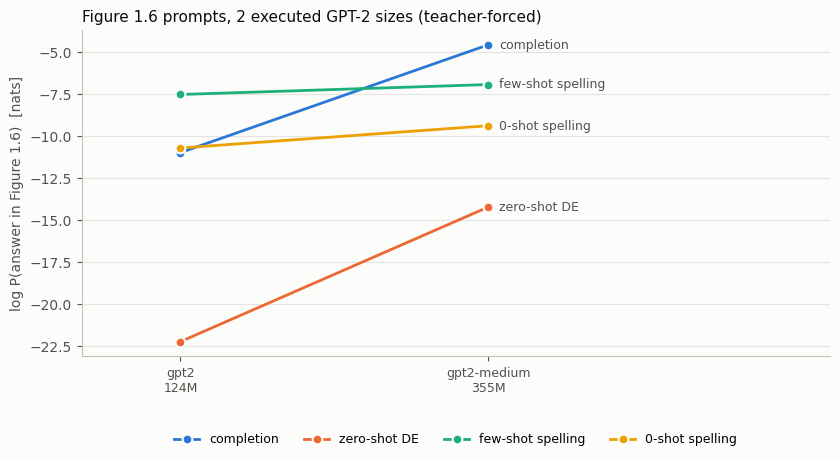

In [16]:
SERIES = {"completion": "#2a78d6", "zero-shot DE": "#eb6834",
          "few-shot spelling": "#1baf7a", "0-shot spelling": "#eda100"}
names = list(scale)
x = [scale[n]["params"] for n in names]

fig, ax = plt.subplots(figsize=(8.5, 4.8), facecolor="#fcfcfb")
ax.set_facecolor("#fcfcfb")
for task, color in SERIES.items():
    y = [scale[n][task] for n in names]
    ax.plot(x, y, color=color, lw=2, marker="o", ms=7, mec="#fcfcfb", mew=1.5, label=task)
    ax.annotate(task, (x[-1], y[-1]), xytext=(8, 0), textcoords="offset points",
                va="center", fontsize=9, color="#52514e")
ax.set_xscale("log")
ax.minorticks_off()
ax.set_xticks(x)
ax.set_xticklabels([f"{n}\n{p / 1e6:,.0f}M" for n, p in zip(names, x)], fontsize=9, color="#52514e")
ax.set_xlim(x[0] / 1.4, x[-1] * 3.2)
ax.set_ylabel("log P(answer in Figure 1.6)  [nats]", color="#52514e")
ax.set_title(f"Figure 1.6 prompts, {len(names)} executed GPT-2 sizes (teacher-forced)",
             loc="left", fontsize=11, color="#0b0b0b")
ax.grid(axis="y", color="#e4e3df", lw=0.8)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
for side in ("left", "bottom"):
    ax.spines[side].set_color("#c3c2b7")
ax.tick_params(colors="#52514e")
ax.legend(frameon=False, fontsize=9, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=4)
plt.tight_layout()
plt.show()

Plot ini memvisualkan tabel di atas untuk dua ukuran yang dieksekusi. Keempat garis naik dari 124M ke 355M. Garis `zero-shot DE` paling curam (dari -22.232 ke -14.216) tetapi tetap paling bawah. Garis `few-shot spelling` selalu berada di atas `0-shot spelling` (-7.518 vs -10.706 di 124M, -6.926 vs -9.377 di 355M), dan jaraknya menyempit dari 3.188 ke 2.451 nats. Dengan dua titik, setiap garis hanyalah satu kemiringan; menjalankan sel opsional 774M/1.5B lalu sel plot ini lagi akan memperpanjang setiap garis menjadi empat titik.

In [17]:
print("Figure 1.2 instruction given to base (not instruction-tuned) GPT-2 models, greedy, 30 tokens:")
print(repr(FIG12_PROMPT))
for name, row in scale.items():
    print(f"\n[{name}]\n{row['instruction | greedy']!r}")

Figure 1.2 instruction given to base (not instruction-tuned) GPT-2 models, greedy, 30 tokens:
'Write a 4-line poem containing the words Wisconsin, AI, and pizza.'

[gpt2]
'\n\nThe poem is a short poem that is written in a way that is easy to read. It is written in a way that is easy to'

[gpt2-medium]
'\n\nWrite a 4-line poem containing the words Wisconsin, AI, and pizza.\n\nWrite a 4-line poem containing the words Wisconsin'


Di kedua ukuran yang dieksekusi, instruksi Figure 1.2 tidak dikerjakan. GPT-2 124M menulis komentar tentang puisi lalu mengulang `It is written in a way that is easy to`. GPT-2 355M bahkan tidak berkomentar: ia **menyalin instruksinya sendiri** -- `Write a 4-line poem containing the words Wisconsin` -- seolah prompt itu baris pertama dari daftar perintah yang berulang. Memperbesar model 2.85 kali mengubah gaya kegagalannya, bukan menghasilkan kepatuhan pada instruksi.

Ini konsisten dengan Figure 1.3: kemampuan dasar sesudah pretraining adalah text completion dan few-shot terbatas, sedangkan perilaku asisten seperti di Figure 1.2 berasal dari instruction fine-tuning -- model di screenshot itu adalah ChatGPT, GPT-3 yang sudah di-fine-tune dengan metode InstructGPT. Bab 7 melakukan langkah yang sama pada GPT-2 dengan dataset instruksi.

#### Opsional -- inference 774M dan 1.5B (unexecuted by design)

Sel berikut menjalankan probe yang sama pada `gpt2-large` (774M) dan `gpt2-xl` (1.5B). **Sel ini sengaja tidak dieksekusi di edisi ini**, dan tidak punya output:

- **Waktu unduh**: bobot keduanya sekitar 3.2 GB + 6.4 GB. Di jaringan mesin yang membangun notebook ini, unduhan 1.5 GB GPT-2 355M butuh 560 detik, dan 3.2 GB GPT-2 774M butuh 1,193 detik. Menunggu 6.4 GB GPT-2 1.5B berarti 30-50 menit lagi -- di luar anggaran "UTH murah" untuk bab konsep. Bobot 774M kebetulan selesai terunduh ke cache mesin ini selama pembangunan notebook, tetapi inference-nya tetap tidak dijalankan supaya cakupan edisi ini konsisten: dua model.
- **Memori**: GPT-2 1.5B dalam fp32 butuh sekitar 6.2 GB hanya untuk bobot (1,557,611,200 x 4 byte).
- **Bukan klaim**: tidak ada hasil inference 774M/1.5B di notebook ini (jumlah parameter keduanya di sensus `meta` di atas tidak membutuhkan bobot); tabel, plot, dan teks penjelasan inference di atas hanya memuat dua ukuran yang dieksekusi.
- **Aman untuk Run all**: sel dijaga knob `RUN_LARGER_GPT2 = False`; tanpa mengubah knob, sel hanya mencetak bahwa langkah ini dilewati.

Cara menjalankan: ubah knob menjadi `RUN_LARGER_GPT2 = True`, eksekusi sel di bawah (unduhan cukup sekali; bobot tersimpan di cache Hugging Face), lalu jalankan ulang sel plot dan sel instruksi Figure 1.2 di atas untuk mendapat empat titik.

In [18]:
RUN_LARGER_GPT2 = False
# knob: unexecuted by design in this edition. True = ~9.6 GB extra download (3.2 + 6.4 GB)
#       and ~6.2 GB RAM for gpt2-xl in fp32. False keeps "Run all" cheap.
if RUN_LARGER_GPT2:
    for name in ["gpt2-large", "gpt2-xl"]:     # 774M and 1.5B
        scale[name] = probe_model(name)
    report(scale)
else:
    print("RUN_LARGER_GPT2 = False -> 774M / 1.5B inference skipped")

RUN_LARGER_GPT2 = False -> 774M / 1.5B inference skipped


## 1.7 Membangun large language model

Dengan fondasi konsep di atas, rencana buku ini mengikuti GPT sebagai cetak biru dan memecah pekerjaan menjadi tiga tahap.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/01.Chapter01/figure1.10.png" width="700">

**Figure 1.9** Tiga tahap membangun LLM: (1) persiapan data dan sampling, mekanisme atensi, dan arsitektur; (2) pretraining -- training loop, evaluasi, memuat bobot pretrained -- menghasilkan foundation model; (3) fine-tuning menjadi classifier atau asisten pribadi. (File repo: `figure1.10.png`.)

| Tahap | Langkah di Figure 1.9 | Bab | Yang dibangun |
|---|---|---|---|
| 1 -- Building an LLM | 1) data preparation & sampling | 2 | tokenizer regex sederhana, BPE GPT-2 via `tiktoken`, sliding-window dataloader, embedding |
| | 2) attention mechanism | 3 | self-attention, causal mask, multi-head attention |
| | 3) LLM architecture | 4 | `GPTModel` dan generasi teks |
| 2 -- Foundation model | 4) pretraining, 5) training loop, 6) evaluation, 7) load pretrained weights | 5 | pretraining skala edukatif, memuat bobot GPT-2 terbuka |
| 3 -- Fine-tuning | 8) fine-tuning ke dataset berlabel kelas | 6 | classifier spam |
| | 9) fine-tuning ke dataset instruksi | 7 | model yang mengikuti instruksi |

Pretraining LLM dari nol untuk model sekelas GPT menghabiskan biaya komputasi ribuan hingga jutaan dolar, jadi tahap 2 dijalankan pada dataset kecil untuk tujuan edukasi, lalu disambung dengan memuat bobot model terbuka. Tahap 3 mengarah ke dua pemakaian paling umum di dunia nyata dan riset: menjawab instruksi dan mengklasifikasi teks.

## Summary

- **Self-supervision terukur.** 5,145 token `the-verdict.txt` memberi 5,144 label next-token tanpa anotator. GPT-2 124M pretrained mencapai 3.5413 nats/token (perplexity 34.51); unigram yang di-fit di teks yang sama 6.0106; tebakan buta 10.8249. Konteks bernilai faktor sekitar 11.8 per token.
- **Pretraining tidak mengajarkan kepatuhan.** Base GPT-2 124M dan 355M sama-sama tidak menulis puisi Figure 1.2: yang pertama berkomentar tentang puisi, yang kedua menyalin instruksinya.
- **Encoder vs decoder.** Tumpukan 6+6 transformer orisinal berisi 44,140,544 parameter; setiap decoder layer 1,051,648 lebih besar karena cross-attention. BERT mengisi Figure 1.5 dengan `example` (0.8921) dan `can` (0.9551); tanpa konteks kanan, `example` jatuh ke 0.0253. Causal mask GPT-2 terbukti eksak: logit sebelum titik edit identik bit-per-bit (`torch.equal` = True), sedangkan BERT bergeser 6.942649.
- **Token bukan kata.** 1.097-1.199 token per kata+tanda baca untuk prosa Inggris, 2.333 untuk kalimat Indonesia, 2.556 untuk kalimat Jerman.
- **Table 1.1.** 499 B token cocok; proporsi berjumlah 101%; dengan toleransi pembulatan, hanya WebText2 yang tidak konsisten antara kolom bobot dan kolom epoch paper (3.47 vs 2.90 epoch). 570 GB untuk 410 B token = 1.390 byte/token, jauh di bawah 3.948 byte/token teks Inggris mentah yang terukur; bila CommonCrawl serupa, versi mentahnya sekitar 1.62 TB -- ekstrapolasi bersyarat, bukan pengukuran storage CommonCrawl.
- **Biaya.** 3.14e+23 FLOPs; asumsi Lambda (V100 28 TFLOPS, \$1.50/jam, utilisasi 100%) memberi 355.6 GPU-year dan \$4,672,619 -- asal angka \$4.6 juta, sebuah estimasi kasar di bawah asumsi spesifik, bukan batas bawah. Di mesin yang menjalankan notebook ini: ribuan tahun.
- **Skala.** Proxy GPT-3 berisi 174,604,259,328 parameter, cocok dengan Table D.1. Dari 124M ke 355M (dua ukuran yang dieksekusi), log P keempat jawaban Figure 1.6 naik -- 6.416 nats untuk completion, 8.016 untuk translasi -- tetapi hanya completion yang berbalik benar secara greedy.

**Kalibrasi terhadap buku** (tidak ada errata kode, karena bab ini tanpa listing):

1. Section 1.4: encoder dan decoder dihubungkan oleh encoder-decoder attention (cross-attention), bukan self-attention (Vaswani et al., section 3.2.3); terukur sebagai selisih 1,051,648 parameter antara decoder dan encoder layer (cross-attention 1,050,624 + LayerNorm 1,024).
2. Table 1.1: proporsi berjumlah 101%; di tabel sumbernya (GPT-3 Table 2.2), kolom bobot dan kolom epoch WebText2 tidak konsisten di luar toleransi pembulatan.
3. "410 B token butuh sekitar 570 GB": setara 1.390 byte/token, jauh di bawah sekitar 3.95 byte/token teks Inggris mentah yang terukur, sehingga lebih cocok dengan ukuran terkompresi atau basis penghitungan token yang berbeda. Paper GPT-3 tidak menyebut status kompresi 570 GB, dan pengukuran dua teks Inggris di sini tidak membuktikan format storage CommonCrawl.
4. "\$4.6 juta cloud computing credits": angkanya berasal dari harga sewa V100 termurah dengan utilisasi teoretis 100% (artikel Lambda, lewat thread Reddit yang dituju tautan buku). Sumbernya tidak menyebut credits, dan angkanya estimasi kasar: 28 TFLOPS bukan plafon V100, dan utilisasi riil tidak 100%.
5. Jumlah parameter di paper GPT-2 (117M, 345M, 762M, 1542M) lebih kecil dari hitungan live (124M, 355M, 774M, 1558M).

**Book-match:** 175 B parameter (proxy 174.6 B = Table D.1), 499 B token, `example`/`can` dari BERT dan `' be'` dari GPT-2 di Figure 1.5, `most important meal of the day.` dari GPT-2 355M di Figure 1.6, serta 4,690 dan 5,145 yang identik dengan output bab 2 di companion repo.

**What comes next.** Bab 2 (*Working with Text Data*) membangun pipa input yang di bab ini dipakai sebagai kotak hitam: tokenizer regex dengan vocabulary 1,130 kata, BPE GPT-2 lewat `tiktoken`, sliding window yang membungkus 5,144 pasangan (konteks, target) menjadi batch, serta token embedding dan positional embedding.